# 04 · Clusterização de bairros

Os notebooks anteriores mediram uma associação entre a composição dos crimes e o preço dos imóveis. A clusterização faz outra pergunta: **que perfis de bairro aparecem quando combinamos preço, violência, volume e características do estoque?**

Esta execução agrupa os **424 bairros** aprovados pelo notebook 02. O número de bairros e os perfis podem mudar quando mudarem os dados ou filtros.

A intuição inicial separa quatro quadrantes — caro/barato e maior/menor proporção de crimes violentos. Esses cortes são descritivos; a clusterização testa se aparecem grupos semelhantes considerando as seis variáveis, sem impor esses quadrantes.

In [1]:
import json

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
import seaborn as sns
from scipy.cluster import hierarchy
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

from comum import (
    AQUA, AZUL, CACHE, DIVERGENTE, FORMATO_PERCENTUAL, FORMATO_REAIS, LARANJA, MUDO,
    SUPERFICIE, TINTA, TINTA2, VIOLETA, reais,
)

pio.renderers.default = "plotly_mimetype"

bairros = pd.read_parquet(CACHE / "bairros.parquet")
MES_REFERENCIA = (CACHE / "mes_referencia.txt").read_text(encoding="utf-8").strip()
CORES = [AZUL, LARANJA, AQUA, VIOLETA]

print(f"{len(bairros)} bairros · preços em reais constantes de {MES_REFERENCIA}")

424 bairros · preços em reais constantes de 2026-09


## 1 · As variáveis e por que padronizar

Seis variáveis, escolhidas para cobrir três dimensões diferentes de um bairro:

| variável | dimensão |
|---|---|
| `preco_m2_mediano` | preço |
| `share_violento` | **composição** do crime |
| `log_crimes_total` | **exposição** — volume absoluto de ocorrências |
| `log_violentos_por_1k` | violência normalizada pelo estoque imobiliário |
| `area_mediana` | tipo de imóvel |
| `idade_mediana` | idade do estoque construído |

As duas medidas de crime separadas — composição e exposição — são o que permite o algoritmo distinguir "bairro movimentado onde se furta muito" de "bairro tranquilo onde o pouco que acontece é violento". Essa distinção foi o achado central do notebook 02, e aqui ela é dada ao algoritmo como matéria-prima.

**Padronizar é obrigatório, não cosmético.** O `KMeans` agrupa por distância euclidiana. Sem padronizar, `preco_m2_mediano` varia de 980 a 14.900 e `share_violento` de 0 a 1 — a distância entre dois bairros seria essencialmente a diferença de preço, e as outras cinco variáveis não existiriam para o algoritmo. O `StandardScaler` põe todas em média 0 e desvio 1, de modo que cada uma pese igual.

In [2]:
VARIAVEIS = {
    "preco_m2_mediano": "preço do m² (real)",
    "share_violento": "% de crimes violentos",
    "log_crimes_total": "volume de crimes (log)",
    "log_violentos_por_1k": "violentos por mil transações (log)",
    "area_mediana": "área construída mediana",
    "idade_mediana": "idade mediana do imóvel",
}

dados = bairros.dropna(subset=list(VARIAVEIS)).copy()
X = StandardScaler().fit_transform(dados[list(VARIAVEIS)])
padronizado = pd.DataFrame(X, index=dados.index, columns=list(VARIAVEIS))

print(f"{len(dados)} bairros sem nulos nas seis variáveis (de {len(bairros)})")
dados[list(VARIAVEIS)].describe().T[["min", "50%", "max"]].round(2)

424 bairros sem nulos nas seis variáveis (de 424)


,min,50%,max
preco_m2_mediano,1868.68,4137.35,15439.63
share_violento,0.10,0.40,0.67
log_crimes_total,1.49,2.09,4.08
log_violentos_por_1k,0.85,2.38,4.58
area_mediana,49.00,105.00,465.00
idade_mediana,2.00,24.00,71.00


## 2 · Quantos clusters?

Não existe resposta objetiva, mas existem dois indicadores que, juntos, limitam o chute:

- **Silhueta** — mede, para cada bairro, se ele está mais perto dos bairros do próprio grupo do que dos do grupo vizinho. Vai de −1 a 1; quanto mais alto, melhor separados os grupos. **Tem máximo**, então serve para escolher.
- **Inércia** — soma das distâncias ao centroide do próprio cluster. Cai sempre que se acrescenta um cluster, então nunca tem máximo; serve para procurar o "joelho", o ponto depois do qual acrescentar grupo para de compensar.

Os dois aparecem em painéis separados, não num gráfico de dois eixos y — duas escalas no mesmo gráfico deixariam escolher visualmente onde está o joelho só mexendo nos limites dos eixos.

,silhueta,inércia
k,,
2,0.256,2025.152
3,0.282,1621.536
4,0.240,1400.638
5,0.217,1251.982
6,0.207,1144.962
7,0.207,1048.866
8,0.203,977.940
9,0.213,920.398
10,0.204,860.099


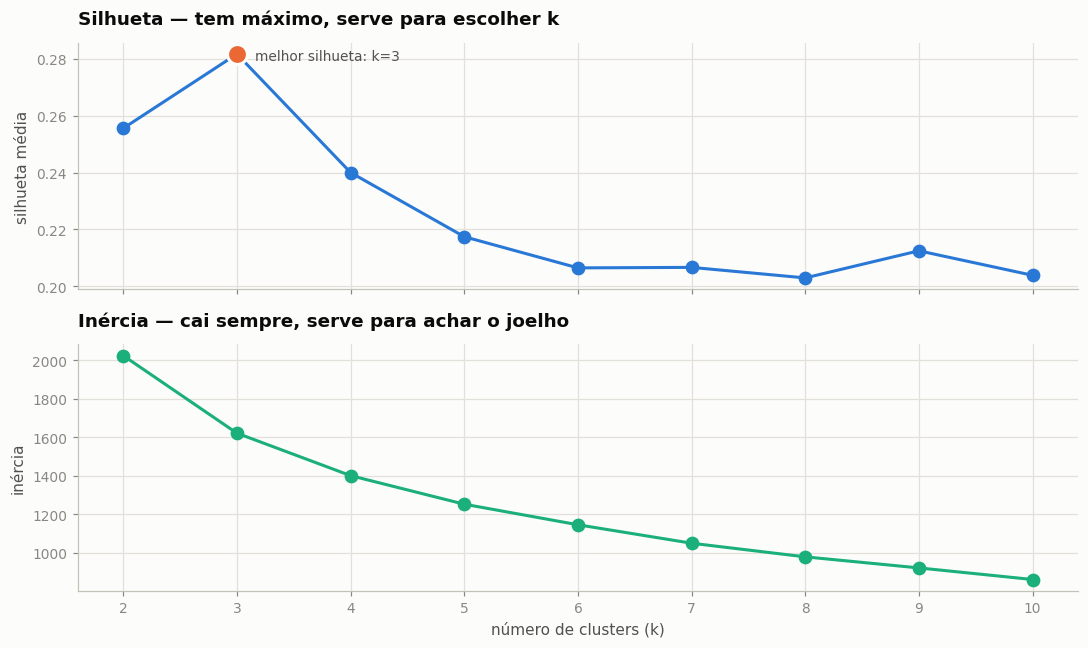

In [3]:
FAIXA_K = range(2, 11)

linhas = []
for k in FAIXA_K:
    modelo = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X)
    linhas.append({"k": k, "silhueta": silhouette_score(X, modelo.labels_), "inércia": modelo.inertia_})
diagnostico = pd.DataFrame(linhas).set_index("k")

K_MELHOR = int(diagnostico["silhueta"].idxmax())

fig, eixos = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

eixos[0].plot(diagnostico.index, diagnostico["silhueta"], color=AZUL, marker="o")
eixos[0].plot(K_MELHOR, diagnostico.loc[K_MELHOR, "silhueta"], "o", color=LARANJA, markersize=13,
              markeredgecolor=SUPERFICIE, markeredgewidth=2)
eixos[0].annotate(f"melhor silhueta: k={K_MELHOR}",
                  (K_MELHOR, diagnostico.loc[K_MELHOR, "silhueta"]),
                  xytext=(12, -4), textcoords="offset points", color=TINTA2, fontsize=9)
eixos[0].set(title="Silhueta — tem máximo, serve para escolher k", ylabel="silhueta média")

eixos[1].plot(diagnostico.index, diagnostico["inércia"], color=AQUA, marker="o")
eixos[1].set(title="Inércia — cai sempre, serve para achar o joelho",
             xlabel="número de clusters (k)", ylabel="inércia")
eixos[1].set_xticks(list(FAIXA_K))

plt.tight_layout()
diagnostico.round(3)

### Validação cruzada: agrupamento hierárquico

A silhueta é um critério; vale conferir com um algoritmo de lógica diferente. O **agrupamento hierárquico de Ward** não precisa de k definido de antemão: ele funde os dois grupos mais parecidos, repetidamente, e o dendrograma mostra a que distância cada fusão aconteceu.

O que procurar: **saltos grandes na altura**. Um salto significa que a fusão juntou coisas muito diferentes, ou seja, que o número de grupos imediatamente antes dela era significativo. Se o maior salto do dendrograma estiver no mesmo k que a silhueta escolheu, os dois métodos concordam.

k com maior salto no dendrograma: 3
k com melhor silhueta no KMeans:  3


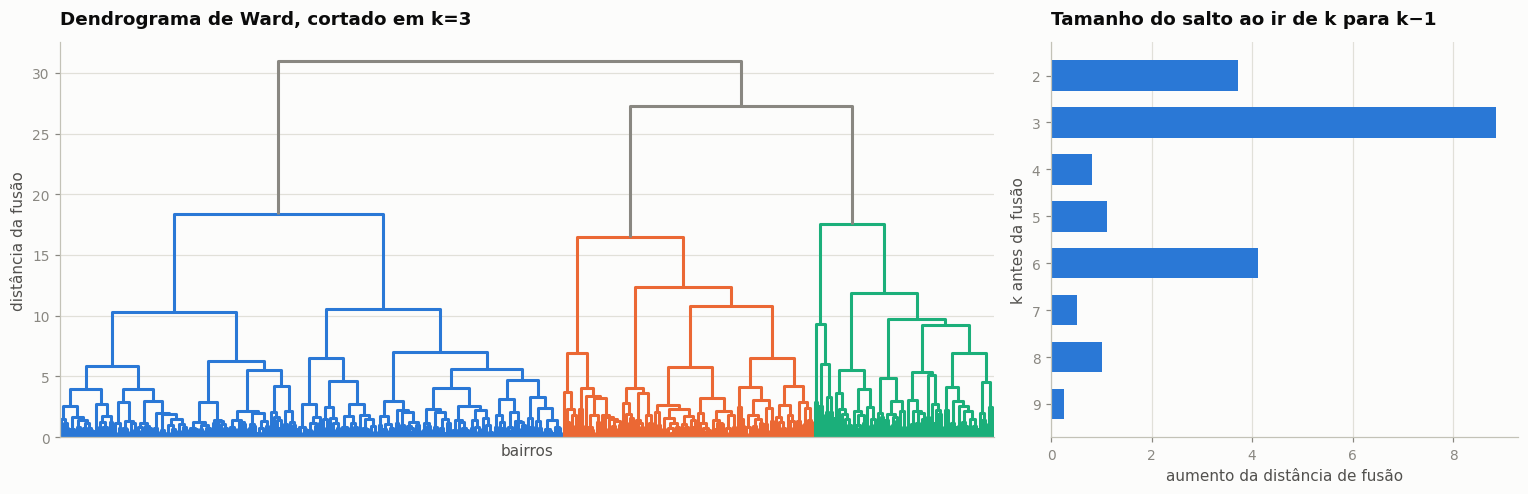

In [4]:
ligacao = hierarchy.linkage(X, method="ward")

fig, (esq, drt) = plt.subplots(1, 2, figsize=(14, 4.6), width_ratios=[2, 1])

hierarchy.set_link_color_palette(CORES)
hierarchy.dendrogram(
    ligacao, ax=esq, no_labels=True, color_threshold=ligacao[-(K_MELHOR - 1), 2],
    above_threshold_color=MUDO,
)
esq.set(title=f"Dendrograma de Ward, cortado em k={K_MELHOR}",
        xlabel="bairros", ylabel="distância da fusão")
esq.grid(axis="x", visible=False)

alturas = ligacao[-9:, 2]
saltos = pd.Series(np.diff(alturas), index=range(10, 1, -1)[1:])
drt.barh(saltos.index.astype(str), saltos.to_numpy(), color=AZUL, height=0.65)
drt.set(title="Tamanho do salto ao ir de k para k−1", xlabel="aumento da distância de fusão",
        ylabel="k antes da fusão")
drt.grid(axis="y", visible=False)

plt.tight_layout()
print(f"k com maior salto no dendrograma: {int(saltos.idxmax())}")
print(f"k com melhor silhueta no KMeans:  {K_MELHOR}")

## 3 · Ajustando os dois agrupamentos

O escolhido pela silhueta e também `k=4`, para confrontar diretamente a intuição dos quatro tipos de bairro.

Os rótulos que o `KMeans` devolve são arbitrários — "cluster 0" não significa nada e muda entre execuções. Por isso os clusters são **renumerados por preço mediano crescente**, o que torna a leitura estável e comparável entre os dois agrupamentos.

In [5]:
def agrupa(matriz, k):
    rotulos = KMeans(n_clusters=k, n_init=20, random_state=42).fit_predict(matriz)
    ordem = (
        pd.Series(dados["preco_m2_mediano"].to_numpy())
        .groupby(rotulos)
        .median()
        .sort_values()
        .index
    )
    renumera = {antigo: novo for novo, antigo in enumerate(ordem)}
    return pd.Series(rotulos, index=dados.index).map(renumera)


for k in sorted({K_MELHOR, 4}):
    dados[f"cluster_{k}"] = agrupa(X, k)

COLUNA_PRINCIPAL = f"cluster_{K_MELHOR}"
dados[[c for c in dados.columns if c.startswith("cluster_")]].apply(
    lambda s: s.value_counts().sort_index()
).fillna(0).astype(int).rename_axis("cluster")

,cluster_3,cluster_4
cluster,,
0,253,197
1,96,95
2,75,113
3,0,19


## 4 · O que cada cluster é

Esta é a parte que dá sentido ao exercício. O heatmap mostra, para cada cluster, a **média padronizada** de cada variável — ou seja, quantos desvios-padrão acima ou abaixo da média da cidade aquele grupo está. Azul é abaixo da média, vermelho acima, cinza em cima da média. É por isso que a rampa é divergente com cinza no meio: aqui o zero significa "igual à cidade", e tem que parecer neutro.

Abaixo do heatmap, uma etiqueta gerada automaticamente lista as duas variáveis em que cada cluster mais se destaca, com o sinal. Ela é objetiva — sai direto dos números, sem interpretação minha — e serve de base para os nomes em prosa que vêm depois.

Etiqueta automática de cada cluster (as duas variáveis mais destacadas):
  cluster 0: volume de crimes (log) baixo · % de crimes violentos alto
  cluster 1: volume de crimes (log) alto · violentos por mil transações (log) alto
  cluster 2: preço do m² (real) alto · área construída mediana alto


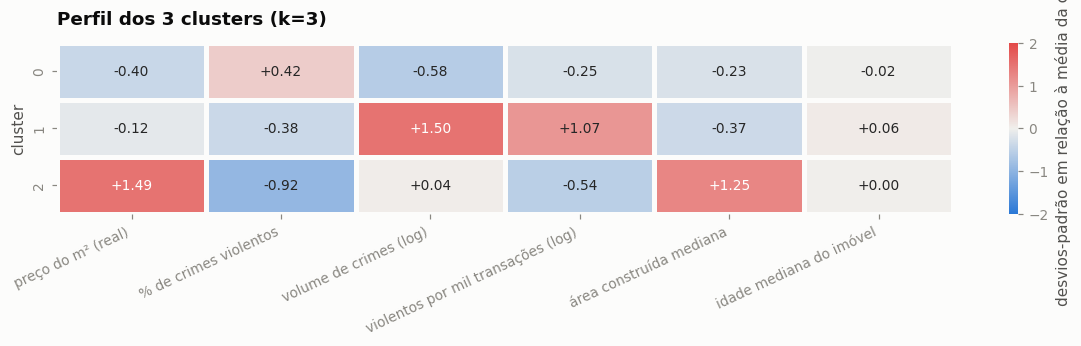

In [6]:
def etiqueta(linha, quantas=2):
    destaques = linha.abs().nlargest(quantas).index
    return " · ".join(
        f"{VARIAVEIS[v]} {'alto' if linha[v] > 0 else 'baixo'}" for v in destaques
    )


perfil = padronizado.groupby(dados[COLUNA_PRINCIPAL]).mean()

fig, eixo = plt.subplots(figsize=(11, 1 + 0.75 * len(perfil)))
sns.heatmap(
    perfil.rename(columns=VARIAVEIS), cmap=DIVERGENTE, center=0, vmin=-2, vmax=2,
    annot=True, fmt="+.2f", annot_kws={"size": 9}, linewidths=2, linecolor=SUPERFICIE,
    cbar_kws={"label": "desvios-padrão em relação à média da cidade"}, ax=eixo,
)
eixo.set(title=f"Perfil dos {len(perfil)} clusters (k={K_MELHOR})", xlabel="", ylabel="cluster")
plt.setp(eixo.get_xticklabels(), rotation=25, ha="right")
plt.tight_layout()

print("Etiqueta automática de cada cluster (as duas variáveis mais destacadas):")
for c, linha in perfil.iterrows():
    print(f"  cluster {c}: {etiqueta(linha)}")

In [7]:
RESUMO = {
    "bairros": ("preco_m2_mediano", "size"),
    "R$/m² mediano": ("preco_m2_mediano", "median"),
    "% violento": ("share_violento", "mean"),
    "crimes/ano": ("crimes_total", "median"),
    "violentos/1k": ("violentos_por_1k", "median"),
    "área (m²)": ("area_mediana", "median"),
    "idade (anos)": ("idade_mediana", "median"),
    "transações": ("n_transacoes", "sum"),
}


def tabela_resumo(coluna):
    return dados.groupby(coluna).agg(**RESUMO)


tabela_resumo(COLUNA_PRINCIPAL).style.format({
    "bairros": "{:,.0f}", "R$/m² mediano": "R$ {:,.0f}", "% violento": "{:.1%}",
    "crimes/ano": "{:,.0f}", "violentos/1k": "{:,.0f}", "área (m²)": "{:,.0f}",
    "idade (anos)": "{:,.0f}", "transações": "{:,.0f}",
}).set_caption("Perfil dos clusters em unidades originais")

,bairros,R$/m² mediano,% violento,crimes/ano,violentos/1k,área (m²),idade (anos),transações
cluster_3,,,,,,,,
0,253,"R$ 3,859",44.1%,72,198,100,24,"74,615"
1,96,"R$ 4,252",35.0%,"2,784","1,028",98,24,"170,078"
2,75,"R$ 6,676",28.8%,202,135,148,23,"81,078"


In [8]:
def representativos(coluna, quantos=6):
    centroides = padronizado.groupby(dados[coluna]).mean()
    distancia = pd.Series(
        np.linalg.norm(padronizado.to_numpy() - centroides.loc[dados[coluna]].to_numpy(), axis=1),
        index=dados.index,
    )
    return (
        distancia.groupby(dados[coluna])
        .nsmallest(quantos)
        .reset_index(level=0, drop=True)
        .groupby(dados[coluna])
        .apply(lambda s: ", ".join(s.index.str.title()))
        .rename("bairros mais típicos do cluster")
    )


representativos(COLUNA_PRINCIPAL).to_frame()

,bairros mais típicos do cluster
cluster_3,
0,"Vila Bancaria, Vila Palmeiras, Vila Buenos Air..."
1,"Vila Medeiros, Vila Maria, Jacana, Penha, Freg..."
2,"Vila Romana, Pompeia, Vila Hamburguesa, Alto D..."


## 5 · Os clusters no plano preço × violência

Este é o gráfico que responde direto à intuição de partida. Os eixos são os dois que a hipótese usava; as cores são os clusters, que o algoritmo formou **sem** saber que esses dois eixos eram os de interesse.

Cada centroide recebe rótulo direto no gráfico, além da legenda — identidade nunca depende só de cor.

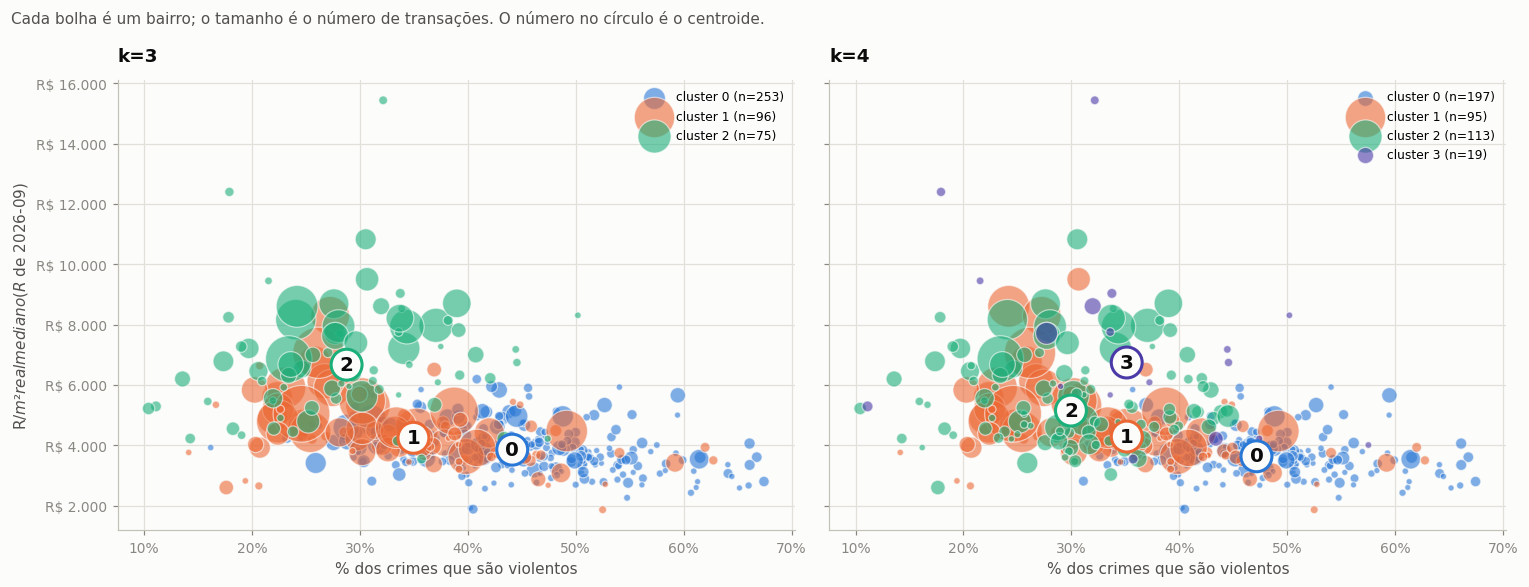

In [9]:
def dispersao_clusters(coluna, eixo):
    for c in sorted(dados[coluna].unique()):
        grupo = dados[dados[coluna] == c]
        eixo.scatter(
            grupo["share_violento"], grupo["preco_m2_mediano"],
            s=grupo["n_transacoes"] / 8 + 12, alpha=0.6, color=CORES[c],
            edgecolor=SUPERFICIE, linewidths=0.8, label=f"cluster {c} (n={len(grupo)})",
        )
        eixo.annotate(
            str(c), (grupo["share_violento"].mean(), grupo["preco_m2_mediano"].median()),
            fontsize=13, fontweight="bold", color=TINTA, ha="center", va="center",
            bbox={"boxstyle": "circle,pad=0.3", "facecolor": SUPERFICIE, "edgecolor": CORES[c], "linewidth": 2},
        )
    eixo.yaxis.set_major_formatter(FORMATO_REAIS)
    eixo.xaxis.set_major_formatter(FORMATO_PERCENTUAL)


colunas_cluster = [c for c in dados.columns if c.startswith("cluster_")]
fig, eixos = plt.subplots(1, len(colunas_cluster), figsize=(7 * len(colunas_cluster), 5.4), sharey=True, squeeze=False)

for eixo, coluna in zip(eixos[0], colunas_cluster):
    dispersao_clusters(coluna, eixo)
    eixo.set(title=f"{coluna.replace('cluster_', 'k=')}", xlabel="% dos crimes que são violentos")
    eixo.legend(loc="upper right", fontsize=8)

eixos[0][0].set_ylabel(f"R$/m² real mediano (R$ de {MES_REFERENCIA})")
fig.suptitle("Cada bolha é um bairro; o tamanho é o número de transações. O número no círculo é o centroide.",
             x=0.01, ha="left", color=TINTA2, fontsize=10)
plt.tight_layout()

as duas componentes somam 57% da variância das seis variáveis


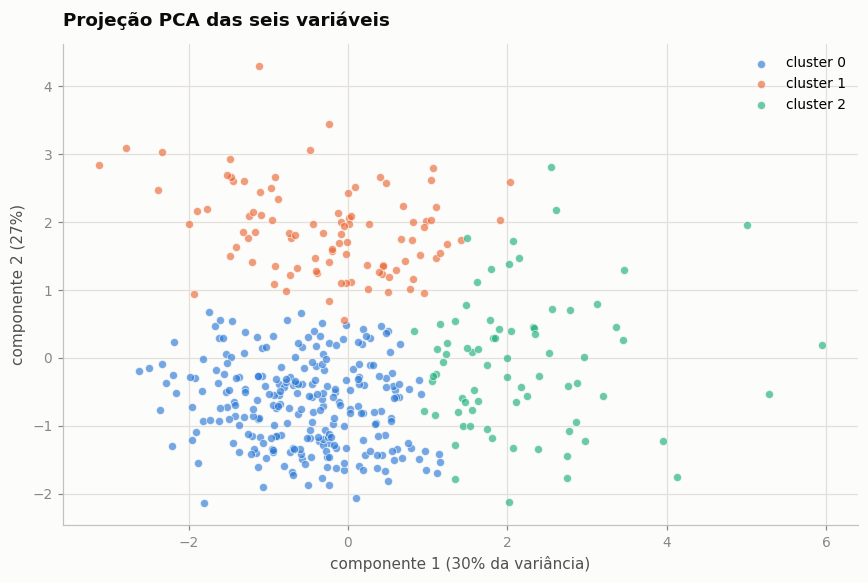

In [10]:
projecao = PCA(n_components=2, random_state=42).fit(X)
coords = projecao.transform(X)
variancia = projecao.explained_variance_ratio_

fig, eixo = plt.subplots(figsize=(8, 5.4))
for c in sorted(dados[COLUNA_PRINCIPAL].unique()):
    marca = (dados[COLUNA_PRINCIPAL] == c).to_numpy()
    eixo.scatter(coords[marca, 0], coords[marca, 1], s=28, alpha=0.65, color=CORES[c],
                 edgecolor=SUPERFICIE, linewidths=0.6, label=f"cluster {c}")

eixo.set(title="Projeção PCA das seis variáveis",
         xlabel=f"componente 1 ({variancia[0]:.0%} da variância)",
         ylabel=f"componente 2 ({variancia[1]:.0%})")
eixo.legend(loc="best", fontsize=9)
plt.tight_layout()

print(f"as duas componentes somam {variancia[:2].sum():.0%} da variância das seis variáveis")

## 6 · Mapas interativos sobre a malha real de São Paulo

Até aqui a geografia apareceu como nuvem de pontos sem referência. Esta seção usa a **malha oficial da Prefeitura**, baixada do GeoSampa no notebook 01: os 96 distritos municipais, em EPSG:4326, com geometria simplificada a 20 metros (de 4 MB para 221 KB de GeoJSON, visualmente idêntica nesta escala).

A atribuição de cada transação ao distrito é **exata, sem inferência nenhuma**:

```
SQL do ITBI → 3 primeiros dígitos = setor fiscal → polígono → distrito
```

Medido: **100,00% das transações** recebem um distrito por esse caminho. É uma geografia de qualidade diferente da usada nas seções anteriores, que dependia de nome de rua e CEP.

**Sobre o volume:** as 312.322 transações têm apenas **5.002 coordenadas distintas**, porque as coordenadas vêm de medianas de rua e centros de bairro. Não há como desenhar 312 mil marcadores — eles não existem como pontos distintos. Os mapas abaixo usam as unidades que de fato existem: 96 distritos preenchidos e 430 bairros como pontos.

**Mapa 1** pinta cada distrito pelo cluster predominante das suas transações e põe os 430 bairros por cima, coloridos pelo próprio cluster. Onde o preenchimento e os pontos discordam, o distrito é internamente heterogêneo — e isso é informação, não erro.

**Mapa 2** pinta cada distrito pela mediana do R$/m² real, que é um valor exato por distrito.

Os dois são interativos: passe o mouse para ver os números, clique na legenda para isolar um cluster, use a roda do mouse para dar zoom. Nenhuma camada de mapa externa é usada — o contorno é desenhado a partir do GeoJSON em cache, então os gráficos funcionam offline.

> **Nota sobre o renderizador.** O notebook usa `pio.renderers.default = "plotly_mimetype"`, que guarda a figura no formato nativo do Plotly. Renderiza no VS Code e no JupyterLab sem instalar nada, e mantém o arquivo em ~1,5 MB. Se você precisar exportar para HTML estático ou abrir no nbviewer, troque para `"plotly_mimetype+notebook"` — funciona em qualquer lugar, mas embute o plotly.js e o notebook passa de 8 MB, o que é ruim de versionar no git.

In [11]:
malha = gpd.read_file(CACHE / "distritos_sp.geojson")
geojson_distritos = json.loads(malha.to_json())
setor_para_distrito = pd.read_parquet(CACHE / "setor_para_distrito.parquet")

transacoes = pd.read_parquet(
    CACHE / "base_modelagem.parquet", columns=["setor_fiscal", "bairro", "preco_m2"]
)
transacoes["setor_fiscal"] = transacoes["setor_fiscal"].astype(str)
transacoes = transacoes.merge(setor_para_distrito[["setor_fiscal", "distrito"]], on="setor_fiscal", how="left")
transacoes["cluster"] = transacoes["bairro"].map(dados[COLUNA_PRINCIPAL])

por_distrito = transacoes.groupby("distrito").agg(
    preco_m2=("preco_m2", "median"),
    transacoes=("preco_m2", "size"),
    bairros=("bairro", "nunique"),
    cluster=("cluster", lambda s: s.mode().iat[0] if s.notna().any() else np.nan),
).reset_index()
por_distrito["cluster"] = por_distrito["cluster"].astype("Int64")

print(f"transações com distrito: {transacoes['distrito'].notna().mean():.2%}")
print(f"distritos com transação: {len(por_distrito)} de {len(malha)}")
por_distrito.sort_values("preco_m2", ascending=False).head(5)

transações com distrito: 100.00%
distritos com transação: 93 de 96


,distrito,preco_m2,transacoes,bairros,cluster
42,JARDIM PAULISTA,8936.481801,7372,16,2
60,PINHEIROS,8862.090437,3888,10,1
33,ITAIM BIBI,8496.422275,12612,25,2
50,MOEMA,8380.505741,9546,18,2
1,ALTO DE PINHEIROS,8309.603557,4605,17,2


In [12]:
centro_bairro = (
    pd.read_parquet(CACHE / "base_modelagem.parquet", columns=["bairro", "lat", "lon"])
    .dropna(subset=["lat", "lon"])
    .groupby("bairro")[["lat", "lon"]]
    .median()
)
pontos = dados.join(centro_bairro).dropna(subset=["lat", "lon"])
clusters = sorted(dados[COLUNA_PRINCIPAL].unique())

LAYOUT_MAPA = {
    "height": 720,
    "margin": {"r": 10, "t": 90, "l": 10, "b": 10},
    "paper_bgcolor": SUPERFICIE,
    "plot_bgcolor": SUPERFICIE,
    "font": {"family": "Segoe UI, sans-serif", "size": 12, "color": TINTA2},
}


def titulo(principal, detalhe):
    return {"text": f"<b>{principal}</b><br><sup>{detalhe}</sup>", "x": 0.01, "xanchor": "left"}


def escala_discreta(quantidade):
    faixas = []
    for c in range(quantidade):
        faixas += [[c / quantidade, CORES[c]], [(c + 1) / quantidade, CORES[c]]]
    return faixas


com_cluster = por_distrito.dropna(subset=["cluster"])

mapa = go.Figure(go.Choropleth(
    geojson=geojson_distritos, locations=com_cluster["distrito"],
    featureidkey="properties.nm_distrito_municipal",
    z=com_cluster["cluster"].astype(float) + 0.5, zmin=0, zmax=len(clusters),
    colorscale=escala_discreta(len(clusters)), showscale=False,
    marker={"line": {"color": SUPERFICIE, "width": 1}, "opacity": 0.45},
    name="distritos", showlegend=False,
    customdata=com_cluster[["cluster", "preco_m2", "transacoes", "bairros"]],
    hovertemplate=(
        "<b>%{location}</b> · distrito do cluster %{customdata[0]}"
        "<br>R$/m² mediano: %{customdata[1]:,.0f}"
        "<br>transações: %{customdata[2]:,.0f}"
        "<br>bairros: %{customdata[3]}<extra></extra>"
    ),
))

for c in clusters:
    bairros_do_cluster = pontos[pontos[COLUNA_PRINCIPAL] == c]
    mapa.add_trace(go.Scattergeo(
        lon=bairros_do_cluster["lon"], lat=bairros_do_cluster["lat"], mode="markers",
        marker={
            "size": np.sqrt(bairros_do_cluster["n_transacoes"]) / 2.2 + 4,
            "color": CORES[c], "line": {"color": SUPERFICIE, "width": 1},
        },
        name=f"cluster {c} ({len(bairros_do_cluster)} bairros)",
        text=bairros_do_cluster.index.str.title(),
        customdata=np.c_[
            bairros_do_cluster["preco_m2_mediano"],
            bairros_do_cluster["share_violento"] * 100,
            bairros_do_cluster["crimes_total"],
            bairros_do_cluster["n_transacoes"],
        ],
        hovertemplate=(
            "<b>%{text}</b> · cluster " + str(c)
            + "<br>R$/m² mediano: %{customdata[0]:,.0f}"
            + "<br>crimes violentos: %{customdata[1]:.0f}%"
            + "<br>ocorrências/ano: %{customdata[2]:,.0f}"
            + "<br>transações: %{customdata[3]:,.0f}<extra></extra>"
        ),
    ))

mapa.update_geos(fitbounds="locations", visible=False, projection_type="mercator")
mapa.update_layout(
    title=titulo(
        "Clusters de bairro sobre os 96 distritos de São Paulo",
        "preenchimento = cluster predominante do distrito · pontos = bairros, tamanho pelo nº de transações",
    ),
    legend={"orientation": "h", "y": -0.02, "x": 0.01},
    **LAYOUT_MAPA,
)
mapa.show()

In [13]:
RAMPA_PRECO = [[0, "#fde8dc"], [0.33, "#f29b70"], [0.66, "#eb6834"], [1, "#8f3414"]]

mapa_preco = go.Figure(go.Choropleth(
    geojson=geojson_distritos, locations=por_distrito["distrito"],
    featureidkey="properties.nm_distrito_municipal",
    z=por_distrito["preco_m2"], colorscale=RAMPA_PRECO,
    marker={"line": {"color": SUPERFICIE, "width": 1}},
    colorbar={"title": {"text": "R$/m²"}, "tickformat": ",.0f", "thickness": 14, "len": 0.7},
    customdata=por_distrito[["transacoes", "bairros"]],
    hovertemplate=(
        "<b>%{location}</b><br>R$/m² mediano: %{z:,.0f}"
        "<br>transações: %{customdata[0]:,.0f}"
        "<br>bairros: %{customdata[1]}<extra></extra>"
    ),
))

mapa_preco.update_geos(fitbounds="locations", visible=False, projection_type="mercator")
mapa_preco.update_layout(
    title=titulo(
        f"Preço real do m² por distrito — R$ de {MES_REFERENCIA}",
        "mediana das transações residenciais de 2022 a 2026, atribuídas pelo setor fiscal do SQL (exato)",
    ),
    **LAYOUT_MAPA,
)
mapa_preco.show()

## 7 · Os quatro quadrantes existem como tipos de bairro?

Agora o confronto direto com a intuição de partida. O quadrante é definido por dois cortes arbitrários — acima ou abaixo da mediana de preço, acima ou abaixo da mediana de violência. O cluster é definido por semelhança em seis dimensões.

Se a intuição dos quatro tipos estiver certa, cada cluster deveria cair predominantemente num quadrante, e os quatro quadrantes deveriam ter cada um o seu cluster. A tabela abaixo mostra se é isso que acontece.

In [14]:
corte_preco = dados["preco_m2_mediano"].median()
corte_violencia = dados["share_violento"].median()

dados["quadrante"] = (
    np.where(dados["preco_m2_mediano"] >= corte_preco, "caro", "barato")
    + " + "
    + np.where(dados["share_violento"] >= corte_violencia, "muita violência", "pouca violência")
)

cruzamento = pd.crosstab(dados["cluster_4"], dados["quadrante"])
concentracao = cruzamento.max(axis=1) / cruzamento.sum(axis=1)

print(f"cortes: preço = {reais(corte_preco)} · violência = {corte_violencia:.1%}\n")
print("concentração de cada cluster no seu quadrante dominante:")
for c, valor in concentracao.items():
    print(f"  cluster {c}: {valor:.0%} em '{cruzamento.loc[c].idxmax()}'")

cruzamento.style.background_gradient(cmap="Blues", axis=None).set_caption(
    "Clusters (k=4) × quadrantes de preço e violência"
)

cortes: preço = R$ 4.137 · violência = 39.5%

concentração de cada cluster no seu quadrante dominante:
  cluster 0: 65% em 'barato + muita violência'
  cluster 1: 48% em 'caro + pouca violência'
  cluster 2: 76% em 'caro + pouca violência'
  cluster 3: 63% em 'caro + pouca violência'


quadrante,barato + muita violência,barato + pouca violência,caro + muita violência,caro + pouca violência
cluster_4,,,,
0,129,24,36,8
1,22,21,6,46
2,0,14,13,86
3,1,1,5,12


In [15]:
ordem_quadrantes = ["barato + muita violência", "barato + pouca violência",
                    "caro + muita violência", "caro + pouca violência"]

comparacao = dados.groupby("quadrante").agg(
    bairros=("preco_m2_mediano", "size"),
    preco=("preco_m2_mediano", "median"),
    crimes_ano=("crimes_total", "median"),
    area=("area_mediana", "median"),
    transacoes=("n_transacoes", "median"),
).reindex(ordem_quadrantes)

comparacao.style.format({
    "bairros": "{:,.0f}", "preco": "R$ {:,.0f}", "crimes_ano": "{:,.0f}",
    "area": "{:,.0f}", "transacoes": "{:,.0f}",
}).set_caption("Os quatro quadrantes, por conta própria")

,bairros,preco,crimes_ano,area,transacoes
quadrante,,,,,
barato + muita violência,152,"R$ 3,535",83,99,157
barato + pouca violência,60,"R$ 3,749",181,100,170
caro + muita violência,60,"R$ 4,726",73,111,228
caro + pouca violência,152,"R$ 5,271",301,117,536


### Veredito: dos quatro tipos imaginados, só um é um tipo de verdade

A concentração de cada cluster no seu quadrante dominante responde a pergunta:

| k=3 | quadrante dominante | concentração |
|---|---|---|
| cluster 2 (miolo valorizado) | caro + pouca violência | **90%** |
| cluster 0 (residencial miúdo) | barato + muita violência | 50% |
| cluster 1 (distrito populoso) | caro + pouca violência | 39% |

| k=4 | quadrante dominante | concentração |
|---|---|---|
| cluster 2 (vertical recente) | caro + pouca violência | **82%** |
| cluster 3 (casarões) | caro + pouca violência | 68% |
| cluster 1 | barato + muita violência | 58% |
| cluster 0 | barato + muita violência | 42% |

**"Caro + pouca violência" é um tipo real** — 90% do cluster 2 cai nele, e o grupo tem identidade própria (imóveis grandes, miolo da cidade, estoque valorizado). Esse quadrante da sua intuição se sustenta.

**Os outros três não são tipos.** Um cluster com 50% ou 39% no quadrante dominante está essencialmente espalhado — metade dele mora em outro quadrante. E o caso mais notável é **"caro + muita violência"**: os 60 bairros que caem nesse quadrante nunca formam a maioria de nenhum cluster, em nenhum dos dois agrupamentos. O máximo que aparece é 7 bairros numa célula. Eles existem, mas são bairros heterogêneos que caíram do mesmo lado de dois cortes arbitrários — não um tipo de lugar.

**Por quê.** A tabela anterior já mostrou: entre os bairros não-caros, o eixo que mais separa um do outro é **tamanho e fluxo**, não violência. Dois bairros podem ter a mesma fração violenta e serem completamente diferentes — um é a Vila Bancária com 74 ocorrências por ano, o outro é a Penha com 2.586. O algoritmo, livre para escolher, separa por essa diferença, porque ela é muito maior.

Ou seja: **violência prevê preço (notebooks 02 e 03), mas não define tipo de bairro.** As duas coisas são compatíveis e não se contradizem — a primeira é sobre a relação entre duas variáveis, a segunda é sobre a estrutura do conjunto. É justamente para isso que serve clusterizar depois de correlacionar.

## 8 · Estabilidade — o quanto confiar nesses grupos

Clusterização sempre devolve clusters, mesmo em dados sem estrutura nenhuma. Antes de dar nome aos grupos, duas checagens honestas:

1. **A silhueta é alta o bastante?** Acima de 0,5 indica estrutura clara; entre 0,25 e 0,5, estrutura fraca mas real; abaixo de 0,25, os grupos são mais um corte conveniente do que tipos naturais.
2. **Os grupos sobrevivem a outra semente e a outra amostra?** O teste abaixo reajusta o modelo em 20 subamostras de 80% dos bairros e mede com que frequência dois bairros que caíram juntos continuam juntos.

In [16]:
gerador = np.random.default_rng(42)
juntos = np.zeros((len(dados), len(dados)))
vezes = np.zeros((len(dados), len(dados)))

for _ in range(20):
    indices = gerador.choice(len(dados), size=int(0.8 * len(dados)), replace=False)
    rotulos = KMeans(n_clusters=K_MELHOR, n_init=10, random_state=int(gerador.integers(1e6))).fit_predict(X[indices])
    mesmo = rotulos[:, None] == rotulos[None, :]
    juntos[np.ix_(indices, indices)] += mesmo
    vezes[np.ix_(indices, indices)] += 1

estabilidade = np.divide(juntos, vezes, out=np.zeros_like(juntos), where=vezes > 0)
original = dados[COLUNA_PRINCIPAL].to_numpy()
mesmo_cluster = original[:, None] == original[None, :]
triangulo = np.triu(np.ones_like(estabilidade, dtype=bool), k=1) & (vezes > 0)

print(f"silhueta em k={K_MELHOR}: {diagnostico.loc[K_MELHOR, 'silhueta']:.3f}")
print()
print("Pares de bairros que o agrupamento final colocou JUNTOS:")
print(f"  continuam juntos em {estabilidade[triangulo & mesmo_cluster].mean():.1%} das reamostragens")
print("Pares que o agrupamento final colocou SEPARADOS:")
print(f"  aparecem juntos em apenas {estabilidade[triangulo & ~mesmo_cluster].mean():.1%} das reamostragens")

silhueta em k=3: 0.282

Pares de bairros que o agrupamento final colocou JUNTOS:
  continuam juntos em 92.6% das reamostragens
Pares que o agrupamento final colocou SEPARADOS:
  aparecem juntos em apenas 3.1% das reamostragens


## 9 · Conclusão

### Quantos grupos, e o quanto confiar

**A silhueta desta execução escolhe k=3** entre os valores testados (melhor silhueta = 0,282, com 424 bairros). A estabilidade e os perfis devem ser recalculados quando mudarem os dados, filtros ou o método de localização.

A silhueta indica separação moderada/fraca: os grupos são cortes úteis para descrever perfis, não categorias naturais com fronteiras nítidas.

### Sobre a localização e os mapas

A atribuição de bairro segue o notebook 02: bairro do ITBI reconhecido, com fallback pelo bairro modal do CEP. As coordenadas de `base_modelagem` são centros medianos das ocorrências por bairro, não pontos dos endereços vendidos.

Nos mapas distritais, a atribuição da transação ao distrito usa outra chave, independente: `SQL → setor_fiscal → distrito` por maior sobreposição de área. Isso permite comparar o nível de bairro com o distrital, mas não é uma validação do antigo dicionário de ruas.

### Limitações deste notebook

- **A clusterização não testa hipótese.** Não tem p-valor, conjunto de teste nem resposta única para `k`; organiza bairros para descrição.
- **Outras variáveis dariam outros grupos.** Renda e população poderiam alterar substancialmente os clusters.
- **`share_violento` é instável em bairros com pouco crime.** O mínimo de ocorrências reduz, mas não elimina, essa incerteza.
- **Todas as seis variáveis pesam igual**, por construção do `StandardScaler`; isso é uma escolha metodológica.
- **O distrito agrega bairros heterogêneos.** A cor do distrito mostra o cluster predominante; os pontos mantêm os perfis dos bairros visíveis.